# Analiza e Trendeve të Tregut të Punës në Teknologji duke përdorur Python

Ky notebook analizon trendet e tregut të punës në fushën e teknologjisë duke përdorur Python.  
Analiza fokusohet në gjuhët programuese, rolet e zhvilluesve, shtetet, llojet e punësimit dhe nivelet e eksperiencës së zhvilluesve.

**Mjetet e përdorura:**

- Python
- Pandas
- Matplotlib

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("../data/developer_programming_trends_2021_2025.csv")

df.head()

,Developer_ID,Age,Country,Coding_Experience_Years,Professional_Experience_Years,DevType,Programming_Languages,Employment,SurveyYear
0,5,25-34 years old,United Kingdom of Great Britain and Northern I...,17,10,"Developer, desktop or enterprise applications;...",Bash/Shell;HTML/CSS;Python;SQL,"Independent contractor, freelancer, or self-em...",2021.0
1,9,25-34 years old,India,6,4,"Developer, front-end",HTML/CSS;JavaScript,Employed part-time,2021.0
2,10,25-34 years old,Sweden,7,4,Data scientist or machine learning specialist,C++;Python,Employed full-time,2021.0
3,11,25-34 years old,United Kingdom of Great Britain and Northern I...,16,10,"Developer, back-end",C#;TypeScript,Employed full-time,2021.0
4,12,25-34 years old,Spain,12,5,"Developer, back-end",Bash/Shell;HTML/CSS;JavaScript;Node.js;SQL;Typ...,Employed full-time,2021.0


In [5]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (96265, 9)


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96265 entries, 0 to 96264
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Developer_ID                   96265 non-null  int64  
 1   Age                            96265 non-null  object 
 2   Country                        96265 non-null  object 
 3   Coding_Experience_Years        96265 non-null  object 
 4   Professional_Experience_Years  96265 non-null  object 
 5   DevType                        96265 non-null  object 
 6   Programming_Languages          96265 non-null  object 
 7   Employment                     96264 non-null  object 
 8   SurveyYear                     96264 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 6.6+ MB


In [7]:
df.columns

Index(['Developer_ID', 'Age', 'Country', 'Coding_Experience_Years',
       'Professional_Experience_Years', 'DevType', 'Programming_Languages',
       'Employment', 'SurveyYear'],
      dtype='object')

In [8]:
df.isnull().sum()

,0
Developer_ID,0
Age,0
Country,0
Coding_Experience_Years,0
Professional_Experience_Years,0
DevType,0
Programming_Languages,0
Employment,1
SurveyYear,1


In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [10]:
df[['Age', 'Country', 'Employment', 'DevType', 'Programming_Languages',
    'Coding_Experience_Years', 'Professional_Experience_Years', 'SurveyYear']].head()

,Age,Country,Employment,DevType,Programming_Languages,Coding_Experience_Years,Professional_Experience_Years,SurveyYear
0,25-34 years old,United Kingdom of Great Britain and Northern I...,"Independent contractor, freelancer, or self-em...","Developer, desktop or enterprise applications;...",Bash/Shell;HTML/CSS;Python;SQL,17,10,2021.0
1,25-34 years old,India,Employed part-time,"Developer, front-end",HTML/CSS;JavaScript,6,4,2021.0
2,25-34 years old,Sweden,Employed full-time,Data scientist or machine learning specialist,C++;Python,7,4,2021.0
3,25-34 years old,United Kingdom of Great Britain and Northern I...,Employed full-time,"Developer, back-end",C#;TypeScript,16,10,2021.0
4,25-34 years old,Spain,Employed full-time,"Developer, back-end",Bash/Shell;HTML/CSS;JavaScript;Node.js;SQL;Typ...,12,5,2021.0


In [11]:
df['Coding_Experience_Years'] = pd.to_numeric(df['Coding_Experience_Years'], errors='coerce')
df['Professional_Experience_Years'] = pd.to_numeric(df['Professional_Experience_Years'], errors='coerce')

In [12]:
df_clean = df.dropna(subset=['Coding_Experience_Years', 'Professional_Experience_Years'])

print("Original number of rows:", len(df))
print("Cleaned number of rows:", len(df_clean))
print("Removed rows:", len(df) - len(df_clean))

Original number of rows: 96265
Cleaned number of rows: 92137
Removed rows: 4128


In [13]:
df_clean.isnull().sum()

,0
Developer_ID,0
Age,0
Country,0
Coding_Experience_Years,0
Professional_Experience_Years,0
DevType,0
Programming_Languages,0
Employment,1
SurveyYear,1


In [14]:
experience_stats = df_clean[['Coding_Experience_Years', 'Professional_Experience_Years']].describe()

experience_stats

,Coding_Experience_Years,Professional_Experience_Years
count,92137.000000,92137.000000
mean,14.823697,9.694477
std,9.581090,8.049817
min,1.000000,1.000000
25%,8.000000,4.000000
50%,12.000000,7.000000
75%,20.000000,14.000000
max,50.000000,50.000000


In [15]:
experience_stats.to_csv("experience_statistics.csv")

files.download("experience_statistics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
languages = df_clean['Programming_Languages'].str.split(';').explode().str.strip()

top_languages = languages.value_counts().head(10)

top_languages


,count
Programming_Languages,
JavaScript,61277
HTML/CSS,49557
SQL,47565
Python,38957
TypeScript,33501
Java,29521
Bash/Shell,27182
C#,27061
PHP,19921


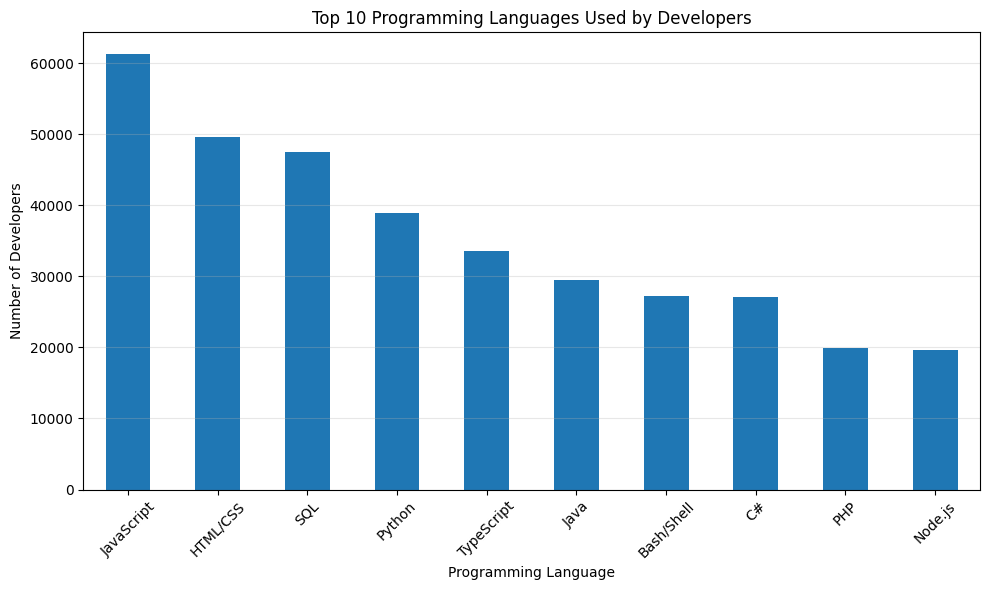

In [17]:
plt.figure(figsize=(10, 6))

top_languages.plot(kind='bar')

plt.title("Top 10 Programming Languages Used by Developers")
plt.xlabel("Programming Language")
plt.ylabel("Number of Developers")
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.savefig("figure_1_top_programming_languages.png", dpi=300)
plt.show()

In [18]:
roles = df_clean['DevType'].str.split(';').explode().str.strip()

top_roles = roles.value_counts().head(10)

top_roles

,count
DevType,
"Developer, full-stack",46953
"Developer, back-end",42628
"Developer, front-end",25307
"Developer, desktop or enterprise applications",15734
"Developer, mobile",13130
DevOps specialist,10659
System administrator,8194
Database administrator,8120
"Developer, embedded applications or devices",6474


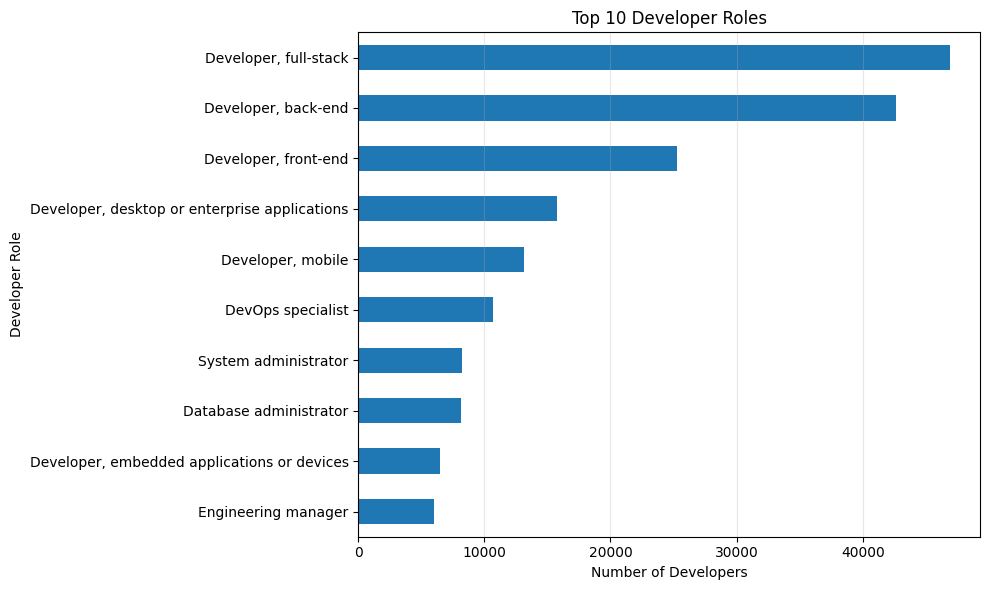

In [19]:
plt.figure(figsize=(10, 6))

top_roles.sort_values().plot(kind='barh')

plt.title("Top 10 Developer Roles")
plt.xlabel("Number of Developers")
plt.ylabel("Developer Role")
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

plt.savefig("figure_2_top_developer_roles.png", dpi=300)
plt.show()

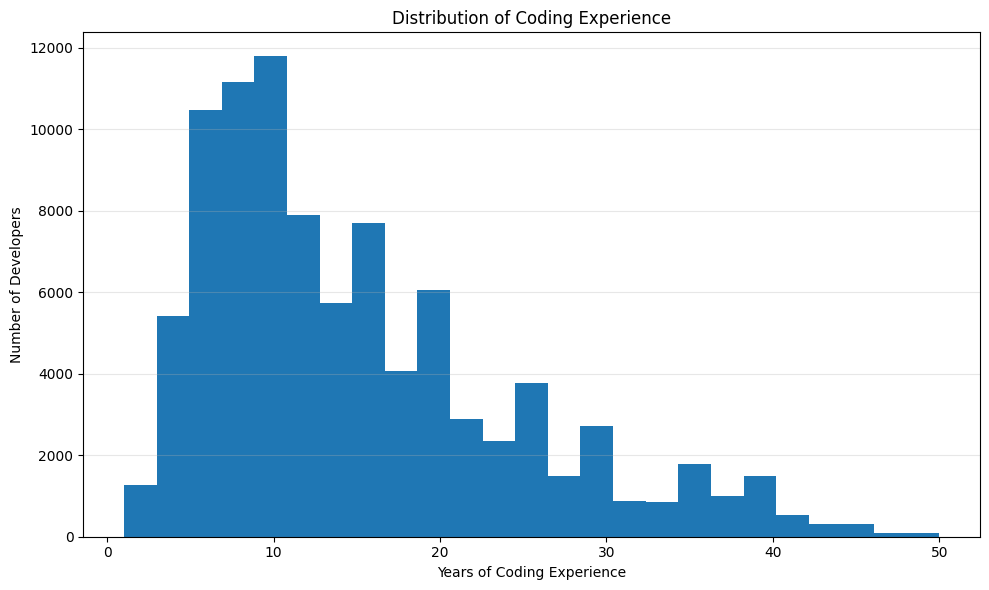

In [20]:
plt.figure(figsize=(10, 6))

df_clean['Coding_Experience_Years'].plot(kind='hist', bins=25)

plt.title("Distribution of Coding Experience")
plt.xlabel("Years of Coding Experience")
plt.ylabel("Number of Developers")
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.savefig("figure_3_coding_experience_distribution.png", dpi=300)
plt.show()

In [21]:
year_counts = df_clean['SurveyYear'].value_counts().sort_index()

year_counts

,count
SurveyYear,
2021.0,56980
2022.0,35156


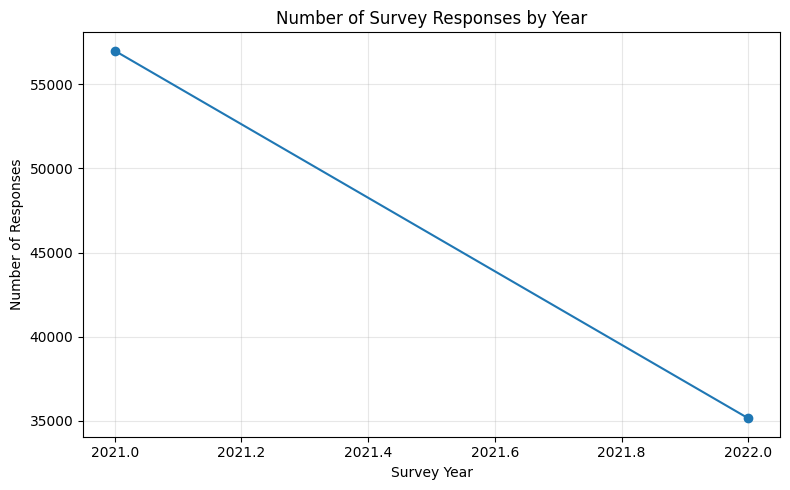

In [22]:
plt.figure(figsize=(8, 5))

year_counts.plot(kind='line', marker='o')

plt.title("Number of Survey Responses by Year")
plt.xlabel("Survey Year")
plt.ylabel("Number of Responses")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("figure_4_survey_responses_by_year.png", dpi=300)
plt.show()

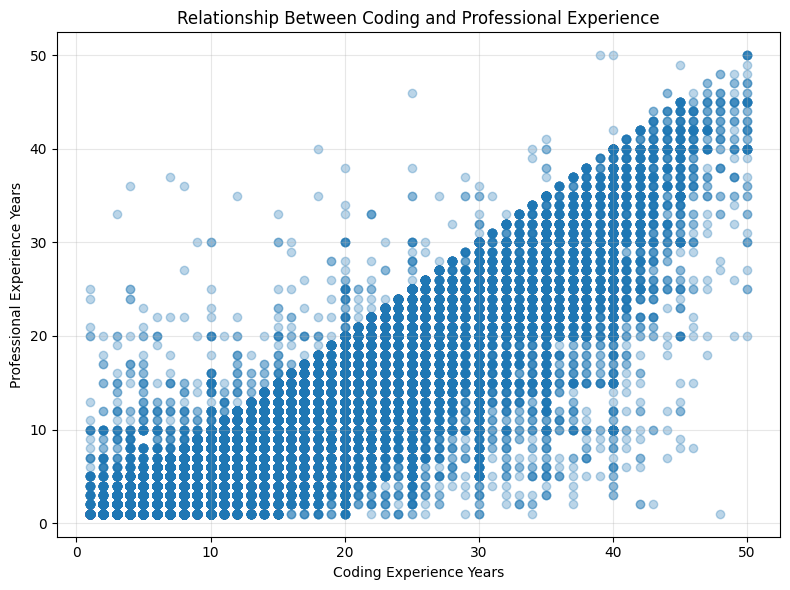

In [23]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df_clean['Coding_Experience_Years'],
    df_clean['Professional_Experience_Years'],
    alpha=0.3
)

plt.title("Relationship Between Coding and Professional Experience")
plt.xlabel("Coding Experience Years")
plt.ylabel("Professional Experience Years")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("figure_5_coding_vs_professional_experience.png", dpi=300)
plt.show()

In [24]:
top_countries = df_clean['Country'].value_counts().head(10)

top_countries

,count
Country,
United States of America,18606
India,8410
Germany,6550
United Kingdom of Great Britain and Northern Ireland,5669
Canada,3359
France,3157
Brazil,2793
Poland,2156
Netherlands,2116


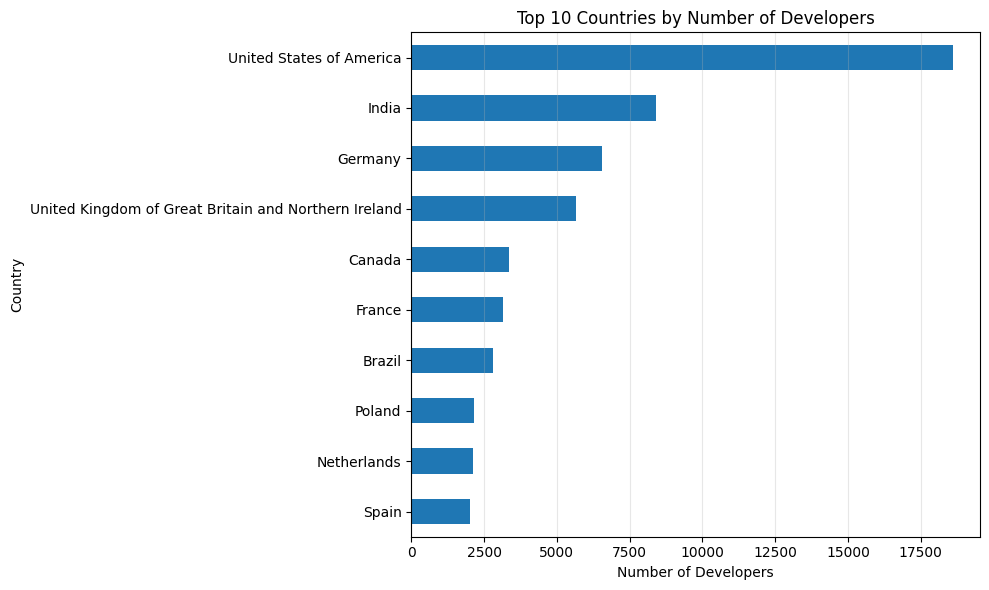

In [25]:
plt.figure(figsize=(10, 6))

top_countries.sort_values().plot(kind='barh')

plt.title("Top 10 Countries by Number of Developers")
plt.xlabel("Number of Developers")
plt.ylabel("Country")
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

plt.savefig("figure_6_top_countries.png", dpi=300)
plt.show()

In [26]:
employment_counts = df_clean['Employment'].value_counts().head(8)

employment_counts

,count
Employment,
Employed full-time,48508
"Employed, full-time",28521
"Independent contractor, freelancer, or self-employed",9895
"Employed, full-time;Independent contractor, freelancer, or self-employed",2492
Employed part-time,1622
"Employed, part-time",586
"Independent contractor, freelancer, or self-employed;Employed, part-time",224
"Employed, full-time;Employed, part-time",147


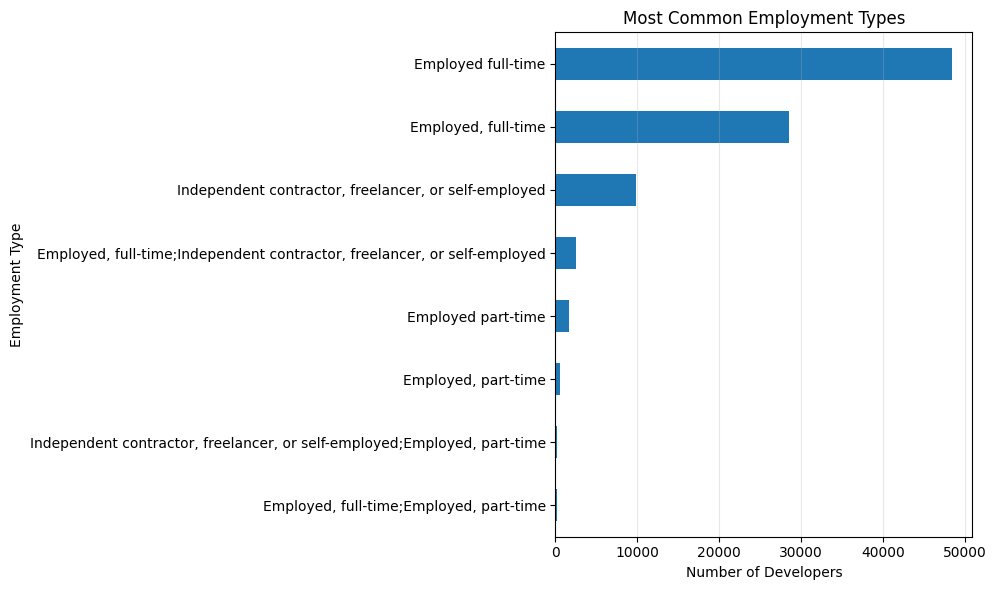

In [27]:
plt.figure(figsize=(10, 6))

employment_counts.sort_values().plot(kind='barh')

plt.title("Most Common Employment Types")
plt.xlabel("Number of Developers")
plt.ylabel("Employment Type")
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

plt.savefig("figure_7_employment_types.png", dpi=300)
plt.show()

In [28]:
avg_experience_by_year = df_clean.groupby('SurveyYear')[['Coding_Experience_Years', 'Professional_Experience_Years']].mean()

avg_experience_by_year

,Coding_Experience_Years,Professional_Experience_Years
SurveyYear,,
2021.0,14.847227,9.484556
2022.0,14.785812,10.034930


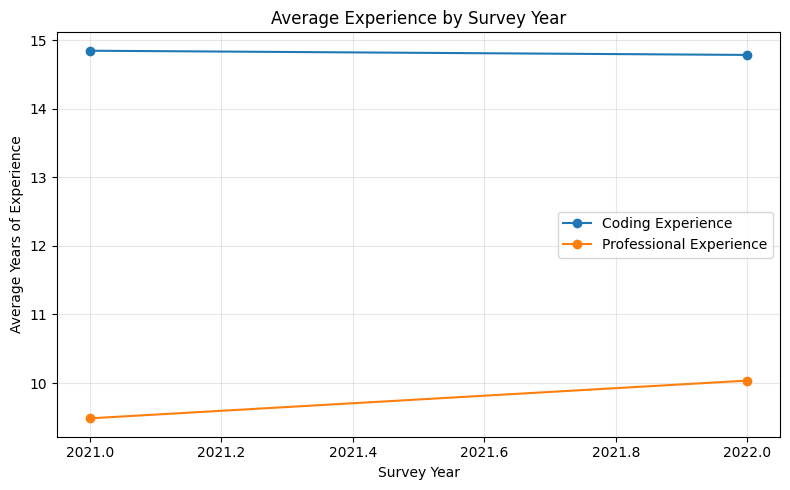

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(
    avg_experience_by_year.index,
    avg_experience_by_year['Coding_Experience_Years'],
    marker='o',
    label='Coding Experience'
)

plt.plot(
    avg_experience_by_year.index,
    avg_experience_by_year['Professional_Experience_Years'],
    marker='o',
    label='Professional Experience'
)

plt.title("Average Experience by Survey Year")
plt.xlabel("Survey Year")
plt.ylabel("Average Years of Experience")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("figure_8_average_experience_by_year.png", dpi=300)
plt.show()

In [30]:
import zipfile

figure_files = [
    "figure_1_top_programming_languages.png",
    "figure_2_top_developer_roles.png",
    "figure_3_coding_experience_distribution.png",
    "figure_4_survey_responses_by_year.png",
    "figure_5_coding_vs_professional_experience.png",
    "figure_6_top_countries.png",
    "figure_7_employment_types.png",
    "figure_8_average_experience_by_year.png"
]

with zipfile.ZipFile("project_figures.zip", "w") as zipf:
    for file in figure_files:
        zipf.write(file)

files.download("project_figures.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
df_clean.to_csv("cleaned_developer_trends_dataset.csv", index=False)

files.download("cleaned_developer_trends_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Përmbledhje përfundimtare

Në këtë notebook është analizuar dataset-i mbi trendet e tregut të punës në teknologji duke përdorur Python.  
Fillimisht, dataset-i është kontrolluar për strukturën e tij, vlerat e munguara dhe rreshtat e duplikuar.  
Kolonat që lidhen me eksperiencën janë konvertuar në format numerik, ndërsa rreshtat me vlera të munguara janë larguar për të siguruar analizë më të saktë.

Janë krijuar disa vizualizime për të analizuar:

- gjuhët programuese më të përdorura;
- rolet më të zakonshme të zhvilluesve;
- shpërndarjen e eksperiencës në kodim;
- numrin e përgjigjeve sipas vitit të anketës;
- lidhjen ndërmjet eksperiencës në kodim dhe eksperiencës profesionale;
- shtetet më të përfaqësuara në dataset;
- llojet e punësimit;
- mesataren e eksperiencës sipas vitit.

Analiza tregon se gjuhët programuese të përdorura në zhvillimin web dhe në inxhinierinë softuerike janë shumë të përfaqësuara. Rolet si zhvillues full-stack, back-end dhe front-end paraqiten si profile të rëndësishme në tregun e punës në teknologji. Gjithashtu, analiza e eksperiencës tregon se ekziston një lidhje ndërmjet viteve të eksperiencës në kodim dhe viteve të eksperiencës profesionale.